In [50]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [51]:
dataset = pd.read_csv('Wine.csv')
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

In [52]:
dataset

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [53]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [54]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [55]:
X_train[0].shape

(13,)

In [56]:
X_train

array([[ 0.87668336,  0.79842885,  0.64412971, ...,  0.0290166 ,
        -1.06412236, -0.2059076 ],
       [-0.36659076, -0.7581304 , -0.39779858, ...,  0.0290166 ,
        -0.73083231, -0.81704676],
       [-1.69689407, -0.34424759, -0.32337513, ...,  0.90197362,
         0.51900537, -1.31256499],
       ...,
       [-0.70227477, -0.68615078, -0.65828065, ...,  0.46549511,
         0.51900537, -1.31256499],
       [ 1.13777093, -0.62316862, -0.91876272, ..., -0.18922266,
         1.03282752,  0.80164614],
       [ 1.4610222 ,  0.12361993,  0.42085937, ..., -1.45501034,
        -1.2168803 , -0.2719767 ]])

In [57]:
#Without PCA:

In [58]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

In [59]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix, accuracy_score
y_pred = classifier.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[14  0  0]
 [ 0 16  0]
 [ 0  0  6]]


1.0

In [60]:
#With PCA:

In [61]:
#Apply PCA
from sklearn.decomposition import PCA
pca = PCA(n_components = 2)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

In [62]:
X_train[0].shape

(2,)

In [64]:
X_train

array([[-2.17884511e+00,  1.07218467e+00],
       [-1.80819239e+00, -1.57822344e+00],
       [ 1.09829474e+00, -2.22124345e+00],
       [-2.55584748e+00,  1.66210369e+00],
       [ 1.85698063e+00, -2.41573166e-01],
       [ 2.58288576e+00,  1.37668170e+00],
       [ 8.72876119e-01, -2.25618512e+00],
       [-4.18384029e-01, -2.35415681e+00],
       [-3.04977245e-01, -2.27659433e+00],
       [ 2.14082532e+00,  1.10052871e+00],
       [-2.98136465e+00,  2.47159183e-01],
       [ 1.96188242e+00, -1.25407738e+00],
       [-2.16177795e+00,  9.75966550e-01],
       [ 2.21976084e+00,  2.39507167e+00],
       [-2.30179529e+00,  2.05791962e-01],
       [-3.00953827e+00,  2.79141212e-01],
       [ 2.63443473e+00,  8.68313119e-01],
       [-1.09219965e+00,  3.53906625e+00],
       [ 2.62578435e+00,  2.96852840e-03],
       [ 1.98077342e-01, -2.29193443e+00],
       [-2.67442753e+00,  2.58800132e+00],
       [-2.54763698e+00,  4.52703891e-01],
       [ 1.77416736e+00, -8.43586940e-01],
       [-2.

In [65]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

In [66]:
from sklearn.metrics import confusion_matrix, accuracy_score
y_pred = classifier.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[14  0  0]
 [ 1 15  0]
 [ 0  0  6]]


0.9722222222222222

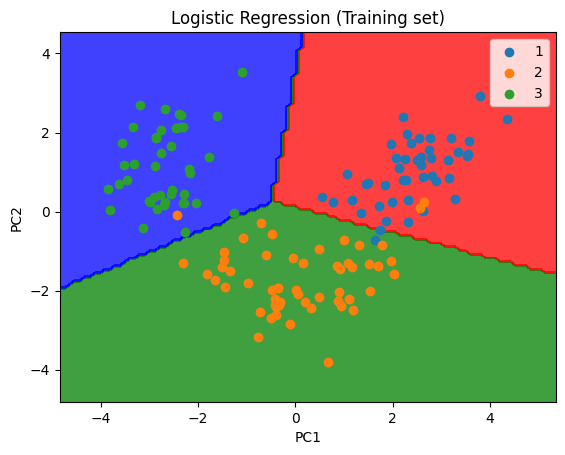

In [67]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap
# Data
X, y = X_train, y_train
# Colormap
cmap = ListedColormap(('red', 'green', 'blue'))
# Plot decision boundary
DecisionBoundaryDisplay.from_estimator(
    classifier,
    X,
    cmap=cmap,
    alpha=0.75
)
# Plot training points
for label in np.unique(y):
    plt.scatter(
        X[y == label, 0],
        X[y == label, 1],
        label=label
    )
# Labels
plt.title('Logistic Regression (Training set)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

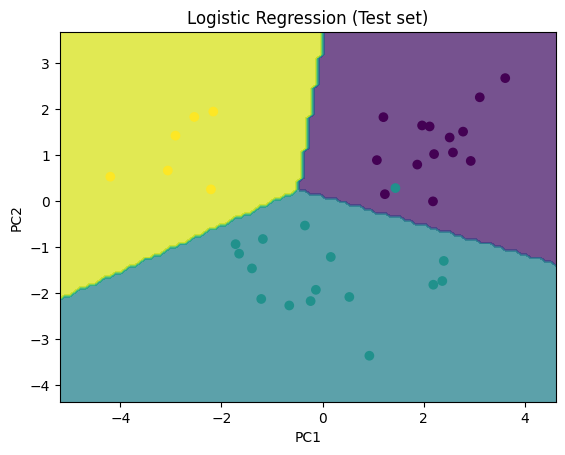

In [68]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
DecisionBoundaryDisplay.from_estimator(classifier, X_test, alpha=0.75)
plt.scatter(X_test[:,0], X_test[:,1], c=y_test)
plt.title('Logistic Regression (Test set)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()